If you find it useful, please cite this article as:

Lin C, Xu J, Hou J, Wang W, Ma Z, Mei X, Fast capacity estimation for production-line screening of inventory battery cells via combined pulsed and dynamic excitation, Energy, https://doi.org/10.1016/j.energy.2026.143168.

In [1]:
import matplotlib
from matplotlib import pyplot as plt
from matplotlib import cm
from matplotlib.ticker import MultipleLocator, FormatStrFormatter
plt.rcParams['font.sans-serif'] = ['Arial']
plt.rcParams['font.size'] = 10.5
plt.rcParams['xtick.direction'] = 'in'
plt.rcParams['ytick.direction'] = 'in'
import seaborn as sns

import numpy as np
import pandas as pd
from tqdm import tqdm
import datetime
import sklearn
from sklearn.metrics import mean_absolute_percentage_error as mape

import scipy
from scipy.ndimage import gaussian_filter1d
from scipy.stats import gaussian_kde
from scipy import stats
from scipy.stats import pearsonr, rankdata, spearmanr

import os
import pickle
import time
import joblib


In [2]:
print("matplotlib: %s"%matplotlib.__version__)
print("numpy: %s"%np.__version__)
print("pandas: %s"%pd.__version__)
print("sklearn: %s"%sklearn.__version__)
print("scipy: %s"%scipy.__version__)

matplotlib: 3.11.1
numpy: 2.4.0
pandas: 3.0.3
sklearn: 1.9.0
scipy: 1.18.0


## LFP cells

### 预处理

In [ ]:
data = joblib.load('./XJTU-EVIR Mixed-excitation datasets/Mixed_excitation_dataset_LFP_61_cells.pkl')
print(type(data), len(data))

<class 'list'> 61


In [4]:
data[0]

,record_number,cycle,step,step_name,step_time,current,voltage,capacity,energy,system_time,time_s
0,1,1,1,搁置,00:00:00.000,0.0,3253.9,0.0,0.0,2026-03-18T10:30:23.088+08:00,0.0
1,2,1,1,搁置,00:00:00.100,0.0,3253.9,0.0,0.0,2026-03-18T10:30:23.088+08:00,0.0
2,3,1,1,搁置,00:00:00.200,0.0,3253.8,0.0,0.0,2026-03-18T10:30:23.188+08:00,0.1
3,4,1,1,搁置,00:00:00.300,0.0,3253.9,0.0,0.0,2026-03-18T10:30:23.288+08:00,0.2
4,5,1,1,搁置,00:00:00.400,0.0,3253.9,0.0,0.0,2026-03-18T10:30:23.388+08:00,0.3
...,...,...,...,...,...,...,...,...,...,...,...
16148,16149,1,15,搁置,00:04:56.000,0.0,3255.1,0.0,0.0,2026-03-18T13:20:21.188+08:00,10198.1
16149,16150,1,15,搁置,00:04:57.000,0.0,3255.1,0.0,0.0,2026-03-18T13:20:22.188+08:00,10199.1
16150,16151,1,15,搁置,00:04:58.000,0.0,3255.0,0.0,0.0,2026-03-18T13:20:23.188+08:00,10200.1
16151,16152,1,15,搁置,00:04:59.000,0.0,3255.0,0.0,0.0,2026-03-18T13:20:24.188+08:00,10201.1


Text(0, 0.5, 'Voltage (V)')

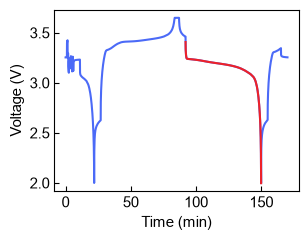

In [5]:
plt.figure(figsize=(8/2.54, 6/2.54))

temp = data[0]
plt.plot(temp["time_s"]/60, temp["voltage"]/1000, color= "#4B6AF7")

temp = temp[temp["step"]==12]  #恒流放电工步
plt.plot(temp["time_s"]/60, temp["voltage"]/1000, color= "#EE2128")

plt.xlabel("Time (min)")
plt.ylabel("Voltage (V)")

In [6]:
Q_list = [] 
for i in tqdm(range(len(data))):
    try:
        temp = data[i]
        temp = temp[temp["step"]==12]  
        Q = list(temp["capacity"])[-1]
    except:
        Q_list.append(0)
    else:     
        Q_list.append(Q)
len(Q_list)

100%|██████████| 61/61 [00:00<00:00, 2231.15it/s]


61

Text(0, 0.5, 'Number of entries')

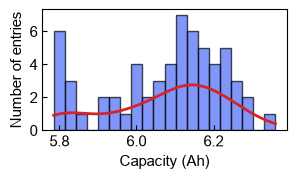

In [7]:
temp_data = np.array(Q_list)/1000

plt.figure(figsize=(8/2.54, 4/2.54))

plt.hist(temp_data, bins=20, alpha=0.7, color='#4B6AF7', edgecolor='black')

kde = gaussian_kde(temp_data)
x_range = np.linspace(min(temp_data), max(temp_data), 200)
plt.plot(x_range, kde(x_range), "#D5252B", linewidth=2)

plt.xlabel("Capacity (Ah)")
plt.ylabel('Number of entries',)


### 特征工程

In [8]:
feas_Q_list = []
for i in range(len(data)):
    cells_data = data[i]
    ocv = cells_data["voltage"].iloc[0]
    cells_data["voltage"] = cells_data["voltage"]-ocv  #初始电压归一化

    #R1 R2
    v0 = cells_data[cells_data["step"]==1]["voltage"].iloc[-1]
    temp = cells_data[cells_data["step"].isin([2])]
    R1 = (temp['voltage'].iloc[10]-v0)/temp['current'].mean()*1000  #1s内阻，毫欧
    R2 = (temp['voltage'].iloc[-1]-temp['voltage'].iloc[10])/temp['current'].mean()*1000  #极化内阻，毫欧
    #R3 R4
    v0 = cells_data[cells_data["step"]==3]["voltage"].iloc[-1]
    temp = cells_data[cells_data["step"].isin([4])]
    R3 = (temp['voltage'].iloc[10]-v0)/temp['current'].mean()*1000  #1s内阻，毫欧
    R4 = (temp['voltage'].iloc[-1]-temp['voltage'].iloc[10])/temp['current'].mean()*1000  #极化内阻，毫欧
    #dv1 dv2
    temp = cells_data[cells_data["step"].isin([3])]
    dv1 = abs(temp["voltage"].iloc[-1] - temp["voltage"].iloc[0])
    temp = cells_data[cells_data["step"].isin([5])]
    dv2 = abs(temp["voltage"].iloc[-1] - temp["voltage"].iloc[0])
    
    #动态工况统计特征
    temp = cells_data[cells_data["step"].isin([6])]
    vol_mean = temp["voltage"].mean()
    vol_var = temp["voltage"].var()
    vol_skew = temp["voltage"].skew()
    vol_kurt = temp["voltage"].kurt()

    feas_Q_list.append(pd.Series([R1, R2, R3, R4, dv1, dv2, vol_mean, vol_var, vol_skew, vol_kurt,  Q_list[i]/1000]))

In [9]:
feas_df = pd.concat(feas_Q_list,axis=1).T
feas_name = ["R1", "R2", "R3", "R4", "dv1", "dv2", "vol_mean", "vol_var", "vol_skew", "vol_kurt"]
feas_df.columns = feas_name + ["Q"]
feas_df

,R1,R2,R3,R4,dv1,dv2,vol_mean,vol_var,vol_skew,vol_kurt,Q
0,18.833865,9.750275,17.350387,14.833665,41.7,72.3,-53.060640,1568.599077,-0.423105,-0.928513,5.7906
1,20.682737,9.766385,19.049894,14.799918,43.2,58.2,-54.429887,1817.280895,-0.430867,-0.926104,6.1364
2,19.050650,9.833669,17.652032,14.251641,41.5,54.1,-50.379453,1553.672061,-0.432179,-0.926431,6.2272
3,18.918032,10.650769,17.318440,15.518256,43.2,56.6,-50.566177,1554.038568,-0.433154,-0.953052,5.9184
4,19.651662,9.784161,18.118853,15.018479,42.3,58.2,-53.964443,1709.126205,-0.428208,-0.931479,6.1483
...,...,...,...,...,...,...,...,...,...,...,...
56,31.275726,9.647653,30.160376,14.113723,45.0,58.9,-63.205867,3832.852240,-0.444595,-0.958039,6.1811
57,18.147875,9.982164,16.715702,15.032466,46.8,61.9,-52.536200,1482.165593,-0.419799,-0.929094,5.8194
58,18.815516,10.699346,17.298645,15.498786,47.4,61.2,-50.659933,1567.585712,-0.426604,-0.965462,6.0540
59,19.036286,10.418282,17.484995,15.018094,44.1,68.9,-46.814467,1582.623640,-0.414301,-1.023793,6.2608


In [10]:
#feas_df.to_csv('./features_csv/feas_df_LFP_cells.csv', index=False)

### ML建模

In [11]:
#ML模型
import sklearn
from sklearn import neighbors
from sklearn.neighbors import KernelDensity
from sklearn import linear_model 
from sklearn.svm import SVR
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import (RBF, Matern, RationalQuadratic, ExpSineSquared, DotProduct, WhiteKernel, ConstantKernel)
from sklearn import tree
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor 

#数据集划分与模型评价
from sklearn.pipeline import Pipeline
from sklearn.pipeline import make_pipeline   
from sklearn.preprocessing import StandardScaler 
from sklearn.model_selection import train_test_split
from sklearn.model_selection import  KFold, StratifiedKFold,GroupKFold, RepeatedKFold
from sklearn.model_selection import GridSearchCV,RandomizedSearchCV,cross_val_score,cross_validate
from sklearn.model_selection import LeaveOneGroupOut, cross_val_predict
from scipy.stats import randint as sp_randint, expon
from sklearn.metrics import mean_squared_error,mean_absolute_error,mean_absolute_percentage_error,r2_score
import pickle

In [12]:
feas_df = pd.read_csv('./features_csv/feas_df_LFP_cells.csv')
feas_df

,R1,R2,R3,R4,dv1,dv2,vol_mean,vol_var,vol_skew,vol_kurt,Q
0,18.833865,9.750275,17.350387,14.833665,41.7,72.3,-53.060640,1568.599077,-0.423105,-0.928513,5.7906
1,20.682737,9.766385,19.049894,14.799918,43.2,58.2,-54.429887,1817.280895,-0.430867,-0.926104,6.1364
2,19.050650,9.833669,17.652032,14.251641,41.5,54.1,-50.379453,1553.672061,-0.432179,-0.926431,6.2272
3,18.918032,10.650769,17.318440,15.518256,43.2,56.6,-50.566177,1554.038568,-0.433154,-0.953052,5.9184
4,19.651662,9.784161,18.118853,15.018479,42.3,58.2,-53.964443,1709.126205,-0.428208,-0.931479,6.1483
...,...,...,...,...,...,...,...,...,...,...,...
56,31.275726,9.647653,30.160376,14.113723,45.0,58.9,-63.205867,3832.852240,-0.444595,-0.958039,6.1811
57,18.147875,9.982164,16.715702,15.032466,46.8,61.9,-52.536200,1482.165593,-0.419799,-0.929094,5.8194
58,18.815516,10.699346,17.298645,15.498786,47.4,61.2,-50.659933,1567.585712,-0.426604,-0.965462,6.0540
59,19.036286,10.418282,17.484995,15.018094,44.1,68.9,-46.814467,1582.623640,-0.414301,-1.023793,6.2608


In [13]:
X_feas = ["R1", "R2", "R3", "R4", "dv1", "dv2", "vol_mean", "vol_var", "vol_skew", "vol_kurt"]
X_all, y_all = feas_df[X_feas], feas_df["Q"]

print(f"训练集大小: {X_all.shape}")
print(f"测试集大小: {y_all.shape}")

训练集大小: (61, 10)
测试集大小: (61,)


In [ ]:
#RFR --using Five-fold nested cross-validation
outer_cv = KFold(n_splits=5, shuffle=True, random_state=2026,)
all_inner_results, all_inner_results_real = [], []
all_outer_test_results, all_outer_test_results_real = [], []

#嵌套交叉验证
for fold, (train_idx, test_idx) in enumerate(outer_cv.split(X_all),start=1,):
    print(f"\n{'=' * 60}")
    print(f"外层第 {fold}/5 折")
    print(f"训练样本数：{len(train_idx)}, "f"测试样本数：{len(test_idx)}")

    X_outer_train = X_all.iloc[train_idx]
    y_outer_train = y_all.iloc[train_idx]
    X_outer_test = X_all.iloc[test_idx]
    y_outer_test = y_all.iloc[test_idx]

    # 内层5折：只在当前内层训练集上选择超参数
    inner_cv = KFold(n_splits=5,shuffle=True,random_state=2026 + fold,)

    pipeline = Pipeline([
        ("scl", StandardScaler()),
        ("rfr",RandomForestRegressor(random_state=2026 + fold, n_jobs=-1),),
    ])

    param = {
            "rfr__n_estimators": [50, 100, 200, 300, 500, 1000],
            "rfr__max_leaf_nodes": list(range(2,11)),
            "rfr__min_samples_split": list(range(2,6)),
            "rfr__min_samples_leaf": list(range(1,6)),
            #"rfr__max_features": ['sqrt', 'log2', None, 0.5, 0.8],
            #"rfr__bootstrap": [True, False]
        }

    search = RandomizedSearchCV(
        estimator=pipeline,
        param_distributions=param,
        n_iter=50,  
        scoring="neg_mean_absolute_percentage_error",
        cv=inner_cv,
        refit=True,
        random_state=2026 + fold,
        n_jobs=-1,
        verbose=1,
        return_train_score=False,
        error_score="raise",
    )

    # 外层测试集不参与任何调参
    search.fit(X_outer_train, y_outer_train)
    best_model = search.best_estimator_
    print("fold%d 最佳参数："%fold, search.best_params_)

    inner_cv_pred = cross_val_predict(
        estimator=best_model,
        X=X_outer_train,
        y=y_outer_train,
        cv=inner_cv,
        method="predict",
        n_jobs=-1
    )

    all_inner_results += list(inner_cv_pred)
    all_inner_results_real += list(y_outer_train)
    #外层测试集
    outer_test_pred = best_model.predict(X_outer_test)
    all_outer_test_results += list(outer_test_pred)
    all_outer_test_results_real += list(y_outer_test)

#预测结果保存
RFR_all_inner_results, RFR_all_inner_results_real = all_inner_results.copy(), all_inner_results_real.copy()
RFR_all_outer_test_results, RFR_all_outer_test_results_real = all_outer_test_results.copy(), all_outer_test_results_real.copy()


外层第 1/5 折
训练样本数：48, 测试样本数：13
Fitting 5 folds for each of 50 candidates, totalling 250 fits
fold1 最佳参数： {'rfr__n_estimators': 200, 'rfr__min_samples_split': 2, 'rfr__min_samples_leaf': 1, 'rfr__max_leaf_nodes': 7}

外层第 2/5 折
训练样本数：49, 测试样本数：12
Fitting 5 folds for each of 50 candidates, totalling 250 fits
fold2 最佳参数： {'rfr__n_estimators': 50, 'rfr__min_samples_split': 4, 'rfr__min_samples_leaf': 4, 'rfr__max_leaf_nodes': 9}

外层第 3/5 折
训练样本数：49, 测试样本数：12
Fitting 5 folds for each of 50 candidates, totalling 250 fits
fold3 最佳参数： {'rfr__n_estimators': 200, 'rfr__min_samples_split': 2, 'rfr__min_samples_leaf': 2, 'rfr__max_leaf_nodes': 8}

外层第 4/5 折
训练样本数：49, 测试样本数：12
Fitting 5 folds for each of 50 candidates, totalling 250 fits
fold4 最佳参数： {'rfr__n_estimators': 50, 'rfr__min_samples_split': 4, 'rfr__min_samples_leaf': 3, 'rfr__max_leaf_nodes': 3}

外层第 5/5 折
训练样本数：49, 测试样本数：12
Fitting 5 folds for each of 50 candidates, totalling 250 fits
fold5 最佳参数： {'rfr__n_estimators': 100, 'rfr__min_sampl

In [15]:
# 测试集结果
y_pred = np.array(RFR_all_outer_test_results)  #RF
y_test = np.array(RFR_all_outer_test_results_real)

ape_list = [
    abs((y_true - y_hat) / y_true) * 100
    for y_true, y_hat in zip(y_test, y_pred)
]
print(np.mean(ape_list))

1.4295294508300123


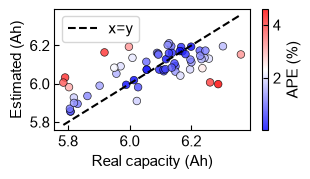

In [16]:
# 容量估计结果图
plt.figure(figsize=(8/2.54, 4/2.54))
plt.scatter(y_test, y_pred, c=ape_list, cmap='bwr', s=30, alpha=0.8, edgecolors='k', linewidth=0.5)

# 添加 x=y 参考线
min_val = min(y_test.min(), y_pred.min())
max_val = max(y_test.max(), y_pred.max())
plt.plot([min_val, max_val], [min_val, max_val], 'k--', linewidth=1.5, label='x=y')

plt.xlabel('Real capacity (Ah)', )
plt.ylabel('Estimated (Ah)',)
plt.legend()

# 添加颜色条
cbar = plt.colorbar()
cbar.set_label('APE (%)', fontsize=10.5)


plt.show()


In [17]:
def misbin_rate_df(y_test, y_pred, bin_min=5.7, bin_max=6.4, bin_width=0.1, max_diff=6):
    """
    分容错档率函数：评估容量真实值y_test和容量估计值y_pred之间的“分箱”错误率；
    bin_min：容量下限
    bin_max：容量上限
    bin_width：
    
    """

    y_test = np.asarray(y_test)
    y_pred = np.asarray(y_pred)

    if len(y_test) != len(y_pred):
        raise ValueError("y_test 和 y_pred 长度必须一致")

    # 计算档位编号
    test_bin = np.floor((y_test - bin_min) / bin_width).astype(int)
    pred_bin = np.floor((y_pred - bin_min) / bin_width).astype(int)

    # 边界处理：确保落在有效档位内
    last_bin = int(np.round((bin_max - bin_min) / bin_width)) - 1
    test_bin = np.clip(test_bin, 0, last_bin)
    pred_bin = np.clip(pred_bin, 0, last_bin)

    diff = np.abs(test_bin - pred_bin)
    total = len(y_test)

    counts = [np.sum(diff == k) for k in range(max_diff + 1)]
    ratios = [c / total for c in counts]

    df = pd.DataFrame({
        "Category": [f"E{k}" for k in range(max_diff + 1)],
        "Count": counts,
        "Proportion": ratios
    })

    return df

测试集评价结果：
MAPE (平均绝对百分比误差): 1.43%
RMSE (均方根误差): 109.67 mAh
Spearmanr correlation: 0.5549


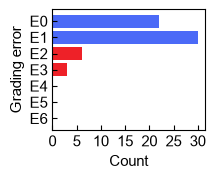

,Category,Count,Proportion
0,E0,22,0.360656
1,E1,30,0.491803
2,E2,6,0.098361
3,E3,3,0.049180
4,E4,0,0.000000
5,E5,0,0.000000
6,E6,0,0.000000


In [18]:
# 分容错档率图
mape = mean_absolute_percentage_error(y_test, y_pred) * 100  # MAPE，单位为%
rmse = np.sqrt(mean_squared_error(y_test, y_pred)) * 1000   
pe = ((y_pred - y_test) / y_test) * 100  
ape = np.abs(pe)

print("=" * 50)
print("测试集评价结果：")
print(f"MAPE (平均绝对百分比误差): {mape:.2f}%")
print(f"RMSE (均方根误差): {rmse:.2f} mAh")
p_corr, p_p = spearmanr(y_test, y_pred)
print(f"Spearmanr correlation: {p_corr:.4f}")
print("=" * 50)


#错档率
df = misbin_rate_df(y_test, y_pred, bin_min=5.7, bin_max=6.4, bin_width=0.1, max_diff=6)  # LFP cells: bin_width = 100 mAh

value_col = "Count"
plt.figure(figsize=(5/2.54, 4/2.54))

bars = plt.barh(df["Category"], df[value_col], color=[ "#4B6AF7", "#4B6AF7","#EE2128", "#EE2128","#EE2128","#EE2128"])
plt.xlabel(value_col)
plt.ylabel("Grading error")

# 让 E0 显示在最上面，E1 在第二行
plt.gca().invert_yaxis()
#横坐标刻度
plt.xticks(np.arange(0, 31, 5))

plt.show()

df

## NCM cells

### 预处理

In [ ]:
data = joblib.load('./XJTU-EVIR Mixed-excitation datasets/Mixed_excitation_dataset_NCM_74_cells.pkl')
print(type(data), len(data))

<class 'list'> 74


In [20]:
data[0]

,record_number,cycle,step,step_name,step_time,current,voltage,capacity,energy,system_time,time_s
0,1,1,1,搁置,00:00:00.000,0.0,3717.7,0.0,0.0,2026-03-23T11:48:52.010+08:00,0.00
1,2,1,1,搁置,00:00:00.100,0.0,3717.7,0.0,0.0,2026-03-23T11:48:52.010+08:00,0.00
2,3,1,1,搁置,00:00:00.200,0.0,3717.6,0.0,0.0,2026-03-23T11:48:52.110+08:00,0.10
3,4,1,1,搁置,00:00:00.300,0.0,3717.6,0.0,0.0,2026-03-23T11:48:52.210+08:00,0.20
4,5,1,1,搁置,00:00:00.400,0.0,3717.6,0.0,0.0,2026-03-23T11:48:52.310+08:00,0.30
...,...,...,...,...,...,...,...,...,...,...,...
18316,18317,1,15,搁置,00:04:56.000,0.0,3484.9,0.0,0.0,2026-03-23T15:14:53.280+08:00,12361.27
18317,18318,1,15,搁置,00:04:57.000,0.0,3484.9,0.0,0.0,2026-03-23T15:14:54.280+08:00,12362.27
18318,18319,1,15,搁置,00:04:58.000,0.0,3484.9,0.0,0.0,2026-03-23T15:14:55.280+08:00,12363.27
18319,18320,1,15,搁置,00:04:59.000,0.0,3484.8,0.0,0.0,2026-03-23T15:14:56.280+08:00,12364.27


In [21]:
Q_list = [] 
for i in tqdm(range(len(data))):
    try:
        temp = data[i]
        temp = temp[temp["step"]==12]  
        Q = list(temp["capacity"])[-1]
    except:
        Q_list.append(0)
    else:     
        Q_list.append(Q)
len(Q_list)

100%|██████████| 74/74 [00:00<00:00, 2198.60it/s]


74

Text(0, 0.5, 'Number of entries')

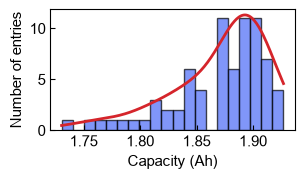

In [22]:
temp_data = np.array(Q_list)/1000

plt.figure(figsize=(8/2.54, 4/2.54))

plt.hist(temp_data, bins=20, alpha=0.7, color='#4B6AF7', edgecolor='black')

kde = gaussian_kde(temp_data)
x_range = np.linspace(min(temp_data), max(temp_data), 200)
plt.plot(x_range, kde(x_range), "#D5252B", linewidth=2)

plt.xlabel("Capacity (Ah)")
plt.ylabel('Number of entries',)

### 特征工程

In [23]:
feas_Q_list = []
for i in range(len(data)):
    cells_data = data[i]
    ocv = cells_data["voltage"].iloc[0]
    cells_data["voltage"] = cells_data["voltage"]-ocv  #初始电压归一化

    #R1 R2
    v0 = cells_data[cells_data["step"]==1]["voltage"].iloc[-1]
    temp = cells_data[cells_data["step"].isin([2])]
    R1 = (temp['voltage'].iloc[10]-v0)/temp['current'].mean()*1000  #1s内阻，毫欧
    R2 = (temp['voltage'].iloc[-1]-temp['voltage'].iloc[10])/temp['current'].mean()*1000  #极化内阻，毫欧
    #R3 R4
    v0 = cells_data[cells_data["step"]==3]["voltage"].iloc[-1]
    temp = cells_data[cells_data["step"].isin([4])]
    R3 = (temp['voltage'].iloc[10]-v0)/temp['current'].mean()*1000  #1s内阻，毫欧
    R4 = (temp['voltage'].iloc[-1]-temp['voltage'].iloc[10])/temp['current'].mean()*1000  #极化内阻，毫欧
    #dv1 dv2
    temp = cells_data[cells_data["step"].isin([3])]
    dv1 = abs(temp["voltage"].iloc[-1] - temp["voltage"].iloc[0])
    temp = cells_data[cells_data["step"].isin([5])]
    dv2 = abs(temp["voltage"].iloc[-1] - temp["voltage"].iloc[0])
    
    #动态工况统计特征
    temp = cells_data[cells_data["step"].isin([6])]
    vol_mean = temp["voltage"].mean()
    vol_var = temp["voltage"].var()
    vol_skew = temp["voltage"].skew()
    vol_kurt = temp["voltage"].kurt()

    feas_Q_list.append(pd.Series([R1, R2, R3, R4, dv1, dv2, vol_mean, vol_var, vol_skew, vol_kurt,  Q_list[i]/1000]))

In [24]:
feas_df = pd.concat(feas_Q_list,axis=1).T
feas_name = ["R1", "R2", "R3", "R4", "dv1", "dv2", "vol_mean", "vol_var", "vol_skew", "vol_kurt"]
feas_df.columns = feas_name + ["Q"]
feas_df

,R1,R2,R3,R4,dv1,dv2,vol_mean,vol_var,vol_skew,vol_kurt,Q
0,53.226609,20.362789,52.168145,25.250715,57.5,56.7,-32.438533,1022.343944,-0.519178,-0.827370,1.8722
1,62.386949,26.471399,60.442871,30.804754,53.6,47.3,-43.221267,1282.222516,-0.529687,-0.782542,1.7955
2,59.583768,22.027938,58.142167,27.807123,67.3,66.1,-35.815467,1248.030888,-0.515421,-0.840346,1.8793
3,58.114989,20.973622,56.030901,25.862553,62.6,59.7,-34.156067,1119.069763,-0.518441,-0.830653,1.8764
4,69.811670,24.863289,69.006451,32.475258,81.1,81.4,-45.083533,1709.771997,-0.524972,-0.819883,1.8475
...,...,...,...,...,...,...,...,...,...,...,...
69,64.458441,26.494336,62.735606,30.881803,70.9,71.2,-44.841895,1349.598244,-0.531032,-0.766668,1.7561
70,49.886407,20.748968,47.636379,24.470933,52.0,51.7,-32.639467,827.471917,-0.514047,-0.811678,1.8731
71,61.525989,23.165993,58.607725,27.553964,51.5,49.3,-37.601733,1208.870124,-0.515692,-0.814872,1.8511
72,67.533399,27.807870,68.255757,43.003627,92.6,113.9,-49.476667,2148.357694,-0.543255,-0.832169,1.8036


In [25]:
#feas_df.to_csv('./features_csv/feas_df_NCM_cells.csv', index=False)

### ML建模

In [26]:
feas_df = pd.read_csv('./features_csv/feas_df_NCM_cells.csv')
feas_df

,R1,R2,R3,R4,dv1,dv2,vol_mean,vol_var,vol_skew,vol_kurt,Q
0,53.226609,20.362789,52.168145,25.250715,57.5,56.7,-32.438533,1022.343944,-0.519178,-0.827370,1.8722
1,62.386949,26.471399,60.442871,30.804754,53.6,47.3,-43.221267,1282.222516,-0.529687,-0.782542,1.7955
2,59.583768,22.027938,58.142167,27.807123,67.3,66.1,-35.815467,1248.030888,-0.515421,-0.840346,1.8793
3,58.114989,20.973622,56.030901,25.862553,62.6,59.7,-34.156067,1119.069763,-0.518441,-0.830653,1.8764
4,69.811670,24.863289,69.006451,32.475258,81.1,81.4,-45.083533,1709.771997,-0.524972,-0.819883,1.8475
...,...,...,...,...,...,...,...,...,...,...,...
69,64.458441,26.494336,62.735606,30.881803,70.9,71.2,-44.841895,1349.598244,-0.531032,-0.766668,1.7561
70,49.886407,20.748968,47.636379,24.470933,52.0,51.7,-32.639467,827.471917,-0.514047,-0.811678,1.8731
71,61.525989,23.165993,58.607725,27.553964,51.5,49.3,-37.601733,1208.870124,-0.515692,-0.814872,1.8511
72,67.533399,27.807870,68.255757,43.003627,92.6,113.9,-49.476667,2148.357694,-0.543255,-0.832169,1.8036


In [27]:
X_feas = ["R1", "R2", "R3", "R4", "dv1", "dv2", "vol_mean", "vol_var", "vol_skew", "vol_kurt"]
X_all, y_all = feas_df[X_feas], feas_df["Q"]

print(f"训练集大小: {X_all.shape}")
print(f"测试集大小: {y_all.shape}")

训练集大小: (74, 10)
测试集大小: (74,)


In [ ]:
#RFR --using Five-fold nested cross-validation
outer_cv = KFold(n_splits=5, shuffle=True, random_state=202610,)
all_inner_results, all_inner_results_real = [], []
all_outer_test_results, all_outer_test_results_real = [], []

#嵌套交叉验证
for fold, (train_idx, test_idx) in enumerate(outer_cv.split(X_all),start=1,):
    print(f"\n{'=' * 60}")
    print(f"外层第 {fold}/5 折")
    print(f"训练样本数：{len(train_idx)}, "f"测试样本数：{len(test_idx)}")

    X_outer_train = X_all.iloc[train_idx]
    y_outer_train = y_all.iloc[train_idx]
    X_outer_test = X_all.iloc[test_idx]
    y_outer_test = y_all.iloc[test_idx]

    # 内层5折：只在当前外层训练集上选择超参数
    inner_cv = KFold(n_splits=5,shuffle=True,random_state=2026 + fold,)

    pipeline = Pipeline([
        ("scl", StandardScaler()),
        ("rfr",RandomForestRegressor(random_state=2026 + fold, n_jobs=-1),),
    ])

    param = {
            "rfr__n_estimators": [50, 100, 200, 300, 500, 1000],
            "rfr__max_leaf_nodes": list(range(2,21,2)),
            "rfr__min_samples_split": list(range(2,6)),
            "rfr__min_samples_leaf": list(range(1,6)),
            #"rfr__max_features": ['sqrt', 'log2', None, 0.5, 0.8],
            #"rfr__bootstrap": [True, False]
        }

    search = RandomizedSearchCV(
        estimator=pipeline,
        param_distributions=param,
        n_iter=50,  
        scoring="neg_mean_absolute_percentage_error",
        cv=inner_cv,
        refit=True,
        random_state=2026 + fold,
        n_jobs=-1,
        verbose=1,
        return_train_score=False,
        error_score="raise",
    )

    # 外层测试集不参与任何调参
    search.fit(X_outer_train, y_outer_train)
    best_model = search.best_estimator_
    print("fold%d 最佳参数："%fold, search.best_params_)

    inner_cv_pred = cross_val_predict(
        estimator=best_model,
        X=X_outer_train,
        y=y_outer_train,
        cv=inner_cv,
        method="predict",
        n_jobs=-1
    )

    all_inner_results += list(inner_cv_pred)
    all_inner_results_real += list(y_outer_train)
    #外层测试集
    outer_test_pred = best_model.predict(X_outer_test)
    all_outer_test_results += list(outer_test_pred)
    all_outer_test_results_real += list(y_outer_test)

#预测结果保存
RFR_all_inner_results, RFR_all_inner_results_real = all_inner_results.copy(), all_inner_results_real.copy()
RFR_all_outer_test_results, RFR_all_outer_test_results_real = all_outer_test_results.copy(), all_outer_test_results_real.copy()


外层第 1/5 折
训练样本数：59, 测试样本数：15
Fitting 5 folds for each of 50 candidates, totalling 250 fits
fold1 最佳参数： {'rfr__n_estimators': 300, 'rfr__min_samples_split': 2, 'rfr__min_samples_leaf': 2, 'rfr__max_leaf_nodes': 8}

外层第 2/5 折
训练样本数：59, 测试样本数：15
Fitting 5 folds for each of 50 candidates, totalling 250 fits
fold2 最佳参数： {'rfr__n_estimators': 200, 'rfr__min_samples_split': 4, 'rfr__min_samples_leaf': 2, 'rfr__max_leaf_nodes': 16}

外层第 3/5 折
训练样本数：59, 测试样本数：15
Fitting 5 folds for each of 50 candidates, totalling 250 fits
fold3 最佳参数： {'rfr__n_estimators': 100, 'rfr__min_samples_split': 2, 'rfr__min_samples_leaf': 2, 'rfr__max_leaf_nodes': 20}

外层第 4/5 折
训练样本数：59, 测试样本数：15
Fitting 5 folds for each of 50 candidates, totalling 250 fits
fold4 最佳参数： {'rfr__n_estimators': 500, 'rfr__min_samples_split': 5, 'rfr__min_samples_leaf': 3, 'rfr__max_leaf_nodes': 20}

外层第 5/5 折
训练样本数：60, 测试样本数：14
Fitting 5 folds for each of 50 candidates, totalling 250 fits
fold5 最佳参数： {'rfr__n_estimators': 1000, 'rfr__min

In [29]:
y_pred = np.array(RFR_all_outer_test_results)  #RF
y_test = np.array(RFR_all_outer_test_results_real)

ape_list = [
    abs((y_true - y_hat) / y_true) * 100
    for y_true, y_hat in zip(y_test, y_pred)
]
print(np.mean(ape_list))

1.1089518770203652


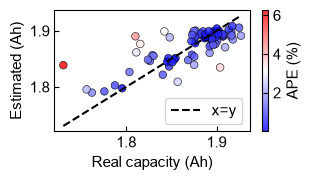

In [30]:
plt.figure(figsize=(8/2.54, 4/2.54))
plt.scatter(y_test, y_pred, c=ape_list, cmap='bwr', s=30, alpha=0.8, edgecolors='k', linewidth=0.5)

# 添加 x=y 参考线
min_val = min(y_test.min(), y_pred.min())
max_val = max(y_test.max(), y_pred.max())
plt.plot([min_val, max_val], [min_val, max_val], 'k--', linewidth=1.5, label='x=y')

plt.xlabel('Real capacity (Ah)', )
plt.ylabel('Estimated (Ah)',)
plt.legend()

# 添加颜色条
cbar = plt.colorbar()
cbar.set_label('APE (%)', fontsize=10.5)

plt.show()

In [31]:
def misbin_rate_df(y_test, y_pred, bin_min=5.7, bin_max=6.4, bin_width=0.1, max_diff=6):
    y_test = np.asarray(y_test)
    y_pred = np.asarray(y_pred)

    if len(y_test) != len(y_pred):
        raise ValueError("y_test 和 y_pred 长度必须一致")

    # 计算档位编号
    test_bin = np.floor((y_test - bin_min) / bin_width).astype(int)
    pred_bin = np.floor((y_pred - bin_min) / bin_width).astype(int)

    # 边界处理：确保落在有效档位内
    last_bin = int(np.round((bin_max - bin_min) / bin_width)) - 1
    test_bin = np.clip(test_bin, 0, last_bin)
    pred_bin = np.clip(pred_bin, 0, last_bin)

    diff = np.abs(test_bin - pred_bin)
    total = len(y_test)

    counts = [np.sum(diff == k) for k in range(max_diff + 1)]
    ratios = [c / total for c in counts]

    df = pd.DataFrame({
        "Category": [f"E{k}" for k in range(max_diff + 1)],
        "Count": counts,
        "Proportion": ratios
    })

    return df

测试集评价结果：
MAPE (平均绝对百分比误差): 1.11%
RMSE (均方根误差): 28.16 mAh
Spearmanr correlation: 0.6267


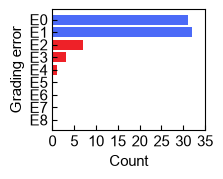

,Category,Count,Proportion
0,E0,31,0.418919
1,E1,32,0.432432
2,E2,7,0.094595
3,E3,3,0.040541
4,E4,1,0.013514
5,E5,0,0.000000
6,E6,0,0.000000
7,E7,0,0.000000
8,E8,0,0.000000


In [32]:
mape = mean_absolute_percentage_error(y_test, y_pred) * 100  
rmse = np.sqrt(mean_squared_error(y_test, y_pred)) * 1000   
pe = ((y_pred - y_test) / y_test) * 100  
ape = np.abs(pe)

print("=" * 50)
print("测试集评价结果：")
print(f"MAPE (平均绝对百分比误差): {mape:.2f}%")
print(f"RMSE (均方根误差): {rmse:.2f} mAh")
p_corr, p_p = spearmanr(y_test, y_pred)
print(f"Spearmanr correlation: {p_corr:.4f}")
print("=" * 50)


#错档率
df = misbin_rate_df(y_test, y_pred, bin_min=1.725, bin_max=1.95, bin_width=0.025, max_diff=8)  # NCM cells: bin_width = 25 mAh

value_col = "Count"
plt.figure(figsize=(5/2.54, 4/2.54))

bars = plt.barh(df["Category"], df[value_col], color=[ "#4B6AF7", "#4B6AF7","#EE2128", "#EE2128","#EE2128","#EE2128"])
plt.xlabel(value_col)
plt.ylabel("Grading error")

# 让 E0 显示在最上面，E1 在第二行
plt.gca().invert_yaxis()
#横坐标刻度
plt.xticks(np.arange(0, 36, 5))

plt.show()
df